Predicting Outpatient Doctor Visits Using Machine Learning
AIT620 Final Examination

Student: Vijay Ravipati

Date:October 24,  2026


### Abstract
The experiment examines the relationship between insurance design, burden of chronic diseases, physical limitations, and. Outpatient physician visits can be predicted by self-reported health. We use 20,190 observations of the RAND Health Insurance Experiment data that are provided by statsmodels. There are descriptive tables and seven visualizations in exploratory analysis. We contrast a dummy baseline, a linear regression, a random forest, and a gradient boosting with the help of.
a held-out test set and five-fold cross-validation. We assess MAE, RMSE and R 2, talk about the errors and limitations, and find out the predictive features. All preprocessing is fit within training pipelines to avoid leakage. This is not causal, but predictive, research.


## Table of Contents
1. [Problem](#problem)
2. [Data Understanding](#data_understanding)
3. [Data Preparation](#data_preparation)
4. [Modeling](#modeling)
5. [Evaluation](#evaluation)
6. [References](#references)
7. [Disclaimer](#disclaimer)

## Problem <a id="problem"></a>
Resource planning can be facilitated by healthcare utilization forecasting. The target is the outpatient physician visits, which are nonnegative number and the target is called mdvis. Our research questions are: (1) How is the visit frequency distributed? (2) What are the available variables relating to visits? (3) How well are visits on unseen data predicted by three supervised regression models? (4) Does the best model have an advantage over predicting the training mean?
Hypothesis: Nonlinear ensemble techniques can be better predictors of error than standard least squares. The current analysis is of an observational nature: there is no causation between predictions and feature importances. The presence of a large percentage of zeros in counts can be a problem to traditional regression.


## Data Understanding <a id="data_understanding"></a>
Source RAND Health Insurance Experiment (RAND HIE), available as the randhie dataset in the open-source Python statsmodels package. Documentation: https://www.statsmodels.org/stable/datasets/generated/randhie.html . The notebook loads the dataset that has been installed locally (neither credentials needed, nor dependencies installed, nor any internet connection needed). The data is publicly reported on the web.
Unit of observation: record of healthcare utilization; 20,190 records and 10 original columns. The target is
`mdvis; the rest of the 9 columns are numeric predictors. The dataset can have several records related to.
individuals, with no individual identifier given here, thus results cannot be construed as patient-independent validation. There are no causal assertions.


In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, statsmodels.api as sm
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__, '| pandas:', pd.__version__)

Python: 3.13.16 | scikit-learn: 1.6.1 | pandas: 2.2.3


In [2]:
df = sm.datasets.randhie.load_pandas().data.copy()
print('Rows, columns:', df.shape)
display(df.head(10))
display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(), 'unique':df.nunique()}))

Rows, columns: (20190, 10)


,mdvis,lncoins,idp,lpi,fmde,physlm,disea,hlthg,hlthf,hlthp
0,0,4.61512,1,6.907755,0.0,0.0,13.73189,1,0,0
1,2,4.61512,1,6.907755,0.0,0.0,13.73189,1,0,0
2,0,4.61512,1,6.907755,0.0,0.0,13.73189,1,0,0
3,0,4.61512,1,6.907755,0.0,0.0,13.73189,1,0,0
4,0,4.61512,1,6.907755,0.0,0.0,13.73189,1,0,0
5,0,4.61512,1,6.907755,0.0,0.0,13.73189,0,0,0
6,0,4.61512,1,6.907755,0.0,0.0,13.73189,0,0,0
7,1,4.61512,1,6.907755,0.0,0.0,13.73189,0,0,0
8,0,4.61512,1,6.907755,0.0,0.0,13.73189,0,0,0
9,0,4.61512,1,6.907755,0.0,0.0,13.73189,0,0,0


,dtype,missing,unique
mdvis,int64,0,59
lncoins,float64,0,5
idp,int64,0,2
lpi,float64,0,619
fmde,float64,0,345
physlm,float64,0,11
disea,float64,0,31
hlthg,int64,0,2
hlthf,int64,0,2
hlthp,int64,0,2


In [3]:
feature_description = pd.DataFrame([
('mdvis','Outpatient physician visits (prediction target)'),
('lncoins','Log(coinsurance percentage + 1)'),
('idp','Individual deductible plan indicator'),
('lpi','Log annual participation incentive payment'),
('fmde','Transformed medical deductible expenditure'),
('physlm','Physical limitation indicator'),
('disea','Number of chronic diseases'),
('hlthg','Self-reported good health indicator'),
('hlthf','Self-reported fair health indicator'),
('hlthp','Self-reported poor health indicator')
],columns=['Variable','Description'])
display(feature_description)
display(df.describe().T.round(3))
print('Duplicate rows:',df.duplicated().sum())
print('Target zeros:', int((df.mdvis==0).sum()), f"({(df.mdvis==0).mean():.1%})")

,Variable,Description
0,mdvis,Outpatient physician visits (prediction target)
1,lncoins,Log(coinsurance percentage + 1)
2,idp,Individual deductible plan indicator
3,lpi,Log annual participation incentive payment
4,fmde,Transformed medical deductible expenditure
5,physlm,Physical limitation indicator
6,disea,Number of chronic diseases
7,hlthg,Self-reported good health indicator
8,hlthf,Self-reported fair health indicator
9,hlthp,Self-reported poor health indicator


,count,mean,std,min,25%,50%,75%,max
mdvis,20190.0,2.860,4.504,0.0,0.000,1.000,4.000,77.000
lncoins,20190.0,1.774,1.983,0.0,0.000,0.000,3.932,4.615
idp,20190.0,0.260,0.439,0.0,0.000,0.000,1.000,1.000
lpi,20190.0,4.708,2.698,0.0,4.064,6.109,6.620,7.164
fmde,20190.0,4.030,3.471,0.0,0.000,6.094,6.959,8.294
physlm,20190.0,0.124,0.322,0.0,0.000,0.000,0.000,1.000
disea,20190.0,11.244,6.741,0.0,6.900,10.576,13.732,58.600
hlthg,20190.0,0.362,0.481,0.0,0.000,0.000,1.000,1.000
hlthf,20190.0,0.077,0.267,0.0,0.000,0.000,0.000,1.000
hlthp,20190.0,0.015,0.121,0.0,0.000,0.000,0.000,1.000


Duplicate rows: 11065
Target zeros: 6308 (31.2%)


### Exploratory Data Analysis (EDA)
Target distribution, categorical composition, feature distributions, correlations, group comparisons, bivariate association and outcome spread are discussed in the following seven numbered charts. All visualizations utilize the original data to describe; only to fit predictive preprocessing and models, training data are utilized.


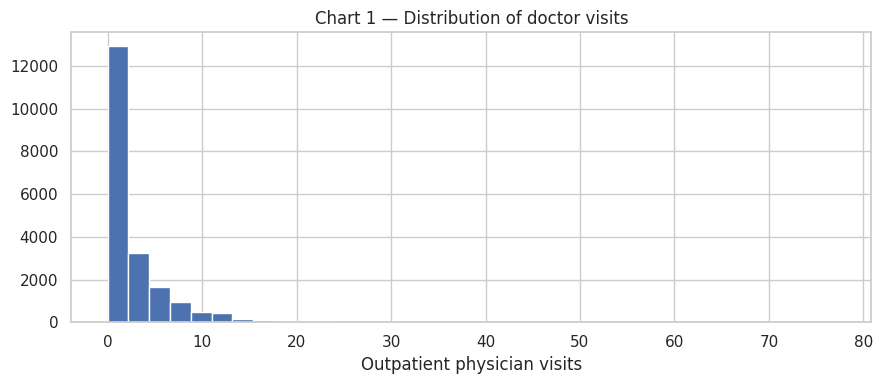

In [4]:
# Chart 1: outpatient visit distribution
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(df['mdvis'],bins=35)
ax.set(xlabel='Outpatient physician visits',title='Chart 1 — Distribution of doctor visits')
plt.tight_layout();plt.show()

,Count
Health status,
Excellent,11019
Good,7309
Fair,1560
Poor,302


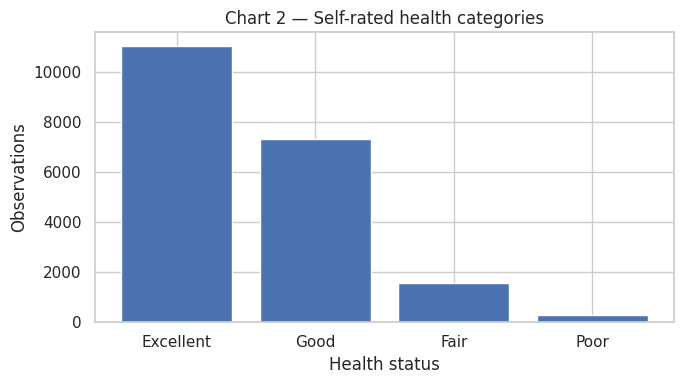

In [5]:
# Chart 2: health status composition
status=np.select([df.hlthp==1,df.hlthf==1,df.hlthg==1],['Poor','Fair','Good'],default='Excellent')
health_counts=pd.Series(status,name='Health status').value_counts()
display(health_counts.to_frame('Count'))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(health_counts.index,health_counts.values)
ax.set(title='Chart 2 — Self-rated health categories',xlabel='Health status',ylabel='Observations')
plt.tight_layout();plt.show()

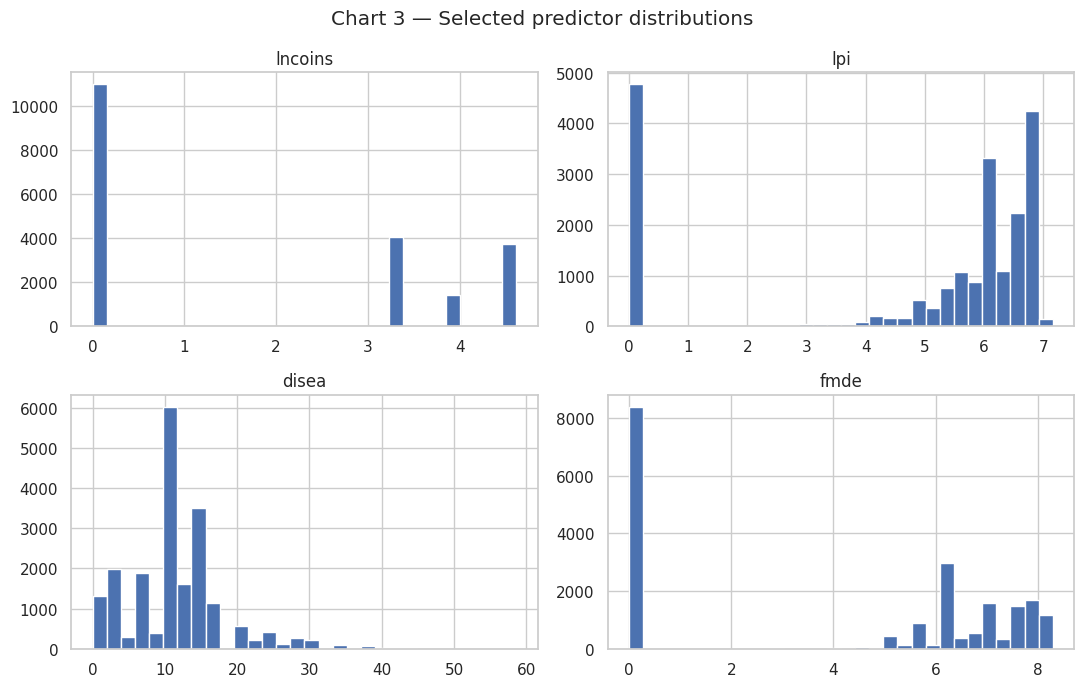

In [6]:
# Chart 3: numeric predictor distributions
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axes.ravel(),['lncoins','lpi','disea','fmde']):
    ax.hist(df[col],bins=30)
    ax.set_title(col)
fig.suptitle('Chart 3 — Selected predictor distributions')
plt.tight_layout();plt.show()

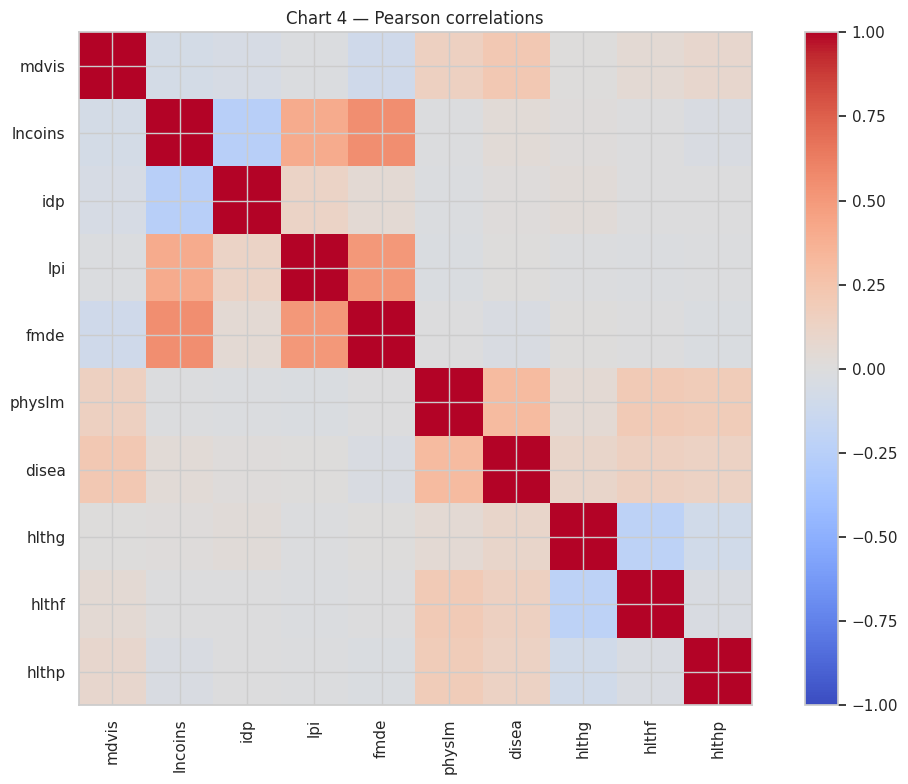

In [7]:
# Chart 4: correlation heatmap
fig,ax=plt.subplots(figsize=(11,8))
im=ax.imshow(df.corr(numeric_only=True),cmap='coolwarm',vmin=-1,vmax=1); ax.set_xticks(range(len(df.columns)),df.columns,rotation=90);ax.set_yticks(range(len(df.columns)),df.columns);fig.colorbar(im,ax=ax)
ax.set_title('Chart 4 — Pearson correlations')
plt.tight_layout();plt.show()

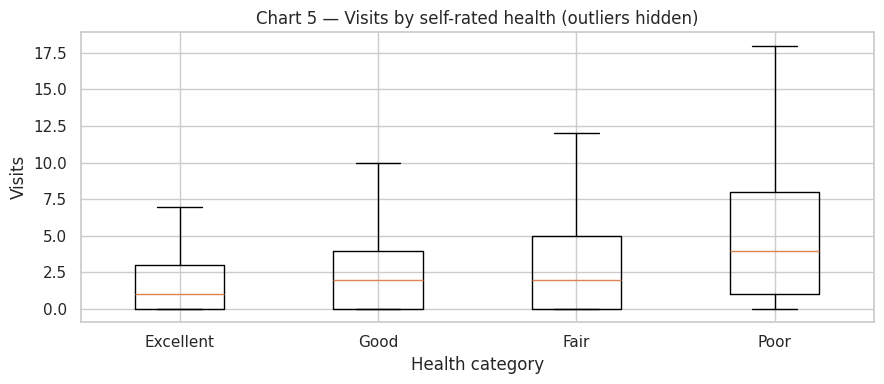

,count,mean,median
HealthStatus,,,
Excellent,11019,2.63,1.0
Fair,1560,3.69,2.0
Good,7309,2.90,2.0
Poor,302,5.79,4.0


In [8]:
# Chart 5: visits by self-rated health
plot_df=df.assign(HealthStatus=status)
fig,ax=plt.subplots(figsize=(9,4))
ax.boxplot([plot_df.loc[plot_df.HealthStatus==s,'mdvis'] for s in ['Excellent','Good','Fair','Poor']],tick_labels=['Excellent','Good','Fair','Poor'],showfliers=False)
ax.set(title='Chart 5 — Visits by self-rated health (outliers hidden)',xlabel='Health category',ylabel='Visits')
plt.tight_layout();plt.show()
display(plot_df.groupby('HealthStatus')['mdvis'].agg(['count','mean','median']).round(2))

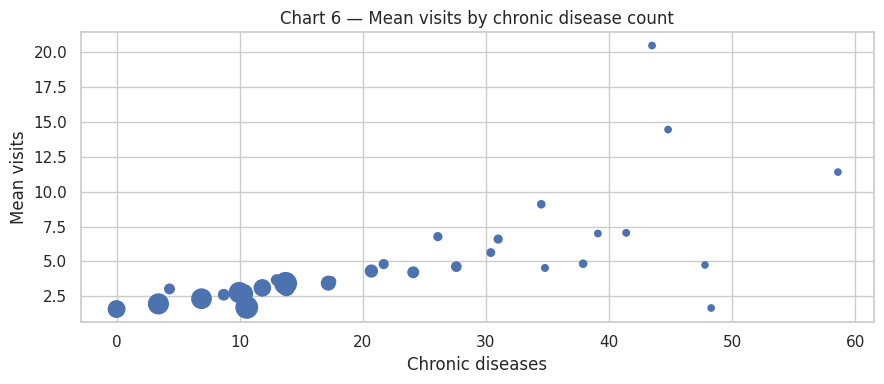

In [9]:
# Chart 6: chronic disease count and visits
summary=df.groupby('disea',as_index=False).agg(mean_visits=('mdvis','mean'),n=('mdvis','size'))
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(summary['disea'],summary['mean_visits'],s=20+220*summary['n']/summary['n'].max())
ax.set(title='Chart 6 — Mean visits by chronic disease count',xlabel='Chronic diseases',ylabel='Mean visits')
plt.tight_layout();plt.show()

,physlm,mean,count
0,0.000,2.582,16751
1,0.022,4.410,134
2,0.027,4.969,128
3,0.028,1.200,5
4,0.033,5.403,129
5,0.043,4.000,9
6,0.130,0.733,15
7,0.144,2.182,537
8,0.157,2.917,72
9,0.198,3.609,23


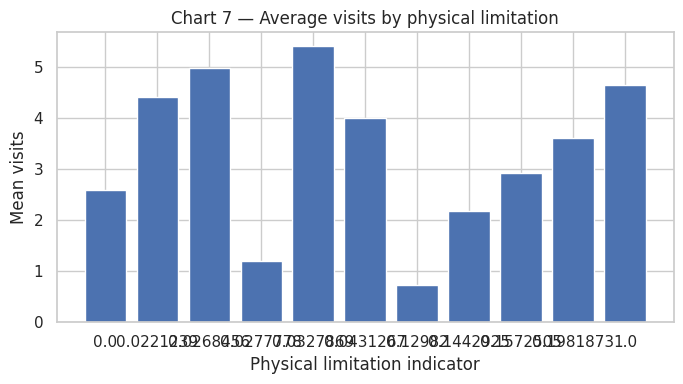

In [10]:
# Chart 7: mean visit count by physical limitation
lim=df.groupby('physlm')['mdvis'].agg(['mean','count']).reset_index()
display(lim.round(3))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(lim['physlm'].astype(str),lim['mean'])
ax.set(title='Chart 7 — Average visits by physical limitation',xlabel='Physical limitation indicator',ylabel='Mean visits')
plt.tight_layout();plt.show()

## Data Preparation <a id="data_preparation"></a>
Predictors and target are separated before splitting. Random state 42 is used to fix an 80/20 train/test split. Any missing numeric values are median-imputed within a pipeline. Linear regression utilizes standardization; tree ensembles do not need scaling. The test set that is held-out is not used to select a model. The independence of the split is constrained by repeated observations, as well as by the absence of group identifiers.


In [11]:
X=df.drop(columns='mdvis')
y=df['mdvis'].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
print('Training:',X_train.shape,'Test:',X_test.shape)
display(pd.DataFrame({'Train':y_train.describe(),'Test':y_test.describe()}).round(2))

Training: (16152, 9) Test: (4038, 9)


,Train,Test
count,16152.00,4038.00
mean,2.82,3.02
std,4.43,4.78
min,0.00,0.00
25%,0.00,0.00
50%,1.00,2.00
75%,4.00,4.00
max,77.00,72.00


## Modeling <a id="modeling"></a>
They are compared to four methods: mean-predicting dummy baseline, standardized linear regression (interpretable linear benchmark), random forest (nonlinear interactions), and histogram gradient boosting (efficient nonlinear boosting). The hyperparameters are predetermined to be compared in a transparent manner; the study does not purport to do exhaustive optimization. The training data are shuffled five times and MAE is used as the main selection metric.


In [12]:
models={
'Dummy mean':Pipeline([('impute',SimpleImputer(strategy='median')),('model',DummyRegressor(strategy='mean'))]),
'Linear regression':Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LinearRegression())]),
'Random forest':Pipeline([('impute',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=100,min_samples_leaf=5,max_features=.8,n_jobs=-1,random_state=RANDOM_STATE))]),
'Gradient boosting':Pipeline([('impute',SimpleImputer(strategy='median')),('model',HistGradientBoostingRegressor(max_iter=120,max_leaf_nodes=15,learning_rate=.07,l2_regularization=1.0,random_state=RANDOM_STATE))])
}
cv=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
rows=[]
for name,model in models.items():
    scores=cross_validate(model,X_train,y_train,cv=cv,scoring={'mae':'neg_mean_absolute_error','r2':'r2'},n_jobs=1)
    rows.append({'Model':name,'CV MAE':-scores['test_mae'].mean(),'CV MAE SD':scores['test_mae'].std(),'CV R²':scores['test_r2'].mean()})
cv_results=pd.DataFrame(rows).sort_values('CV MAE').reset_index(drop=True)
display(cv_results.round(4))
best_name=cv_results.loc[0,'Model']
print('Selected by training CV MAE:',best_name)

,Model,CV MAE,CV MAE SD,CV R²
0,Random forest,2.3822,0.0547,0.1721
1,Gradient boosting,2.4722,0.0420,0.1167
2,Linear regression,2.5561,0.0518,0.0656
3,Dummy mean,2.6922,0.0609,-0.0002


Selected by training CV MAE: Random forest


## Evaluation <a id="evaluation"></a>
All training data are fitted to each model and each model is evaluated once on the test set that is held out. MAE is the mean of the absolute errors in the count of visits (less is good); RMSE is a punishment of big errors (less is good); R2 is an assessment of the improvement over a mean-only reference (greater is good). The nonnegative count outcome is clipped to zero during predictions.
Careful interpretation is needed due to skewness in the number of healthcare visits.


In [13]:
test_rows={}
predictions={}
for name,model in models.items():
    model.fit(X_train,y_train)
    p=np.maximum(0,model.predict(X_test))
    predictions[name]=p
    test_rows[name]={'Test MAE':mean_absolute_error(y_test,p),'Test RMSE':np.sqrt(mean_squared_error(y_test,p)),'Test R²':r2_score(y_test,p)}
test_results=pd.DataFrame.from_dict(test_rows,orient='index').sort_values('Test MAE')
display(test_results.round(4))
print('CV-selected model:',best_name)
print('Its held-out metrics:',test_results.loc[best_name].round(4).to_dict())

,Test MAE,Test RMSE,Test R²
Random forest,2.4647,4.3097,0.1865
Gradient boosting,2.5656,4.4313,0.1399
Linear regression,2.6578,4.6119,0.0684
Dummy mean,2.8231,4.7821,-0.0016


CV-selected model: Random forest
Its held-out metrics: {'Test MAE': 2.4647, 'Test RMSE': 4.3097, 'Test R²': 0.1865}


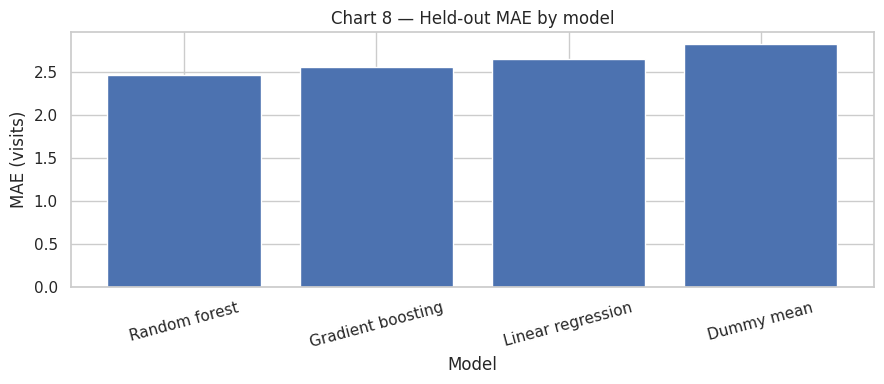

In [14]:
# Chart 8: test model comparison
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(test_results.index,test_results['Test MAE'])
ax.set(title='Chart 8 — Held-out MAE by model',xlabel='Model',ylabel='MAE (visits)')
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()

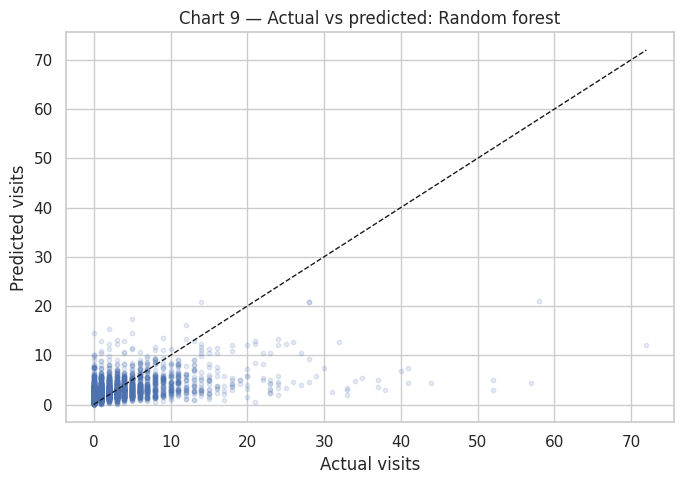

In [15]:
# Chart 9: actual vs predicted for CV-selected model
best_pred=predictions[best_name]
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(y_test,best_pred,alpha=.15,s=10)
upper=max(float(y_test.max()),float(best_pred.max()))
ax.plot([0,upper],[0,upper],'k--',linewidth=1)
ax.set(title=f'Chart 9 — Actual vs predicted: {best_name}',xlabel='Actual visits',ylabel='Predicted visits')
plt.tight_layout();plt.show()

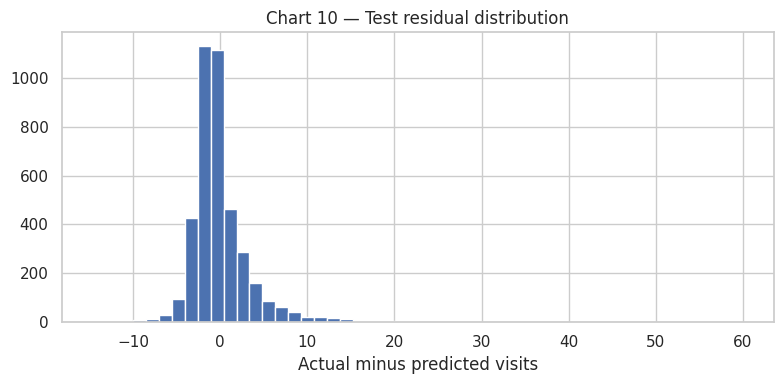

,Statistic,Value
0,Mean residual,0.118
1,Median absolute error,1.634
2,90th percentile absolute error,4.693


In [16]:
# Chart 10: residual diagnostics
residuals=y_test.to_numpy()-best_pred
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(residuals,bins=50)
ax.set(title='Chart 10 — Test residual distribution',xlabel='Actual minus predicted visits')
plt.tight_layout();plt.show()
display(pd.DataFrame({'Statistic':['Mean residual','Median absolute error','90th percentile absolute error'],'Value':[np.mean(residuals),np.median(np.abs(residuals)),np.quantile(np.abs(residuals),.9)]}).round(3))

,Feature,Importance (MAE increase)
5,disea,0.4274
3,fmde,0.2323
2,lpi,0.2126
4,physlm,0.1169
0,lncoins,0.0954
6,hlthg,0.0695
7,hlthf,0.0383
1,idp,0.0333
8,hlthp,0.0068


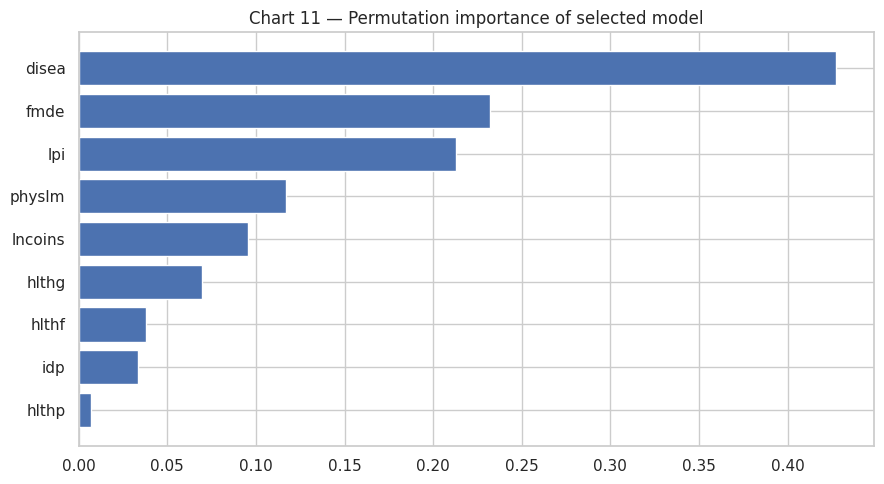

In [17]:
# Permutation importance on held-out observations; descriptive interpretation only
importance=permutation_importance(models[best_name],X_test,y_test,n_repeats=3,random_state=RANDOM_STATE,scoring='neg_mean_absolute_error',n_jobs=1)
importance_df=pd.DataFrame({'Feature':X.columns,'Importance (MAE increase)':importance.importances_mean}).sort_values('Importance (MAE increase)',ascending=False)
display(importance_df.round(4))
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(importance_df.head(10)['Feature'],importance_df.head(10)['Importance (MAE increase)']);ax.invert_yaxis()
ax.set_title('Chart 11 — Permutation importance of selected model')
plt.tight_layout();plt.show()

In [18]:
baseline_mae=float(test_results.loc['Dummy mean','Test MAE'])
selected_mae=float(test_results.loc[best_name,'Test MAE'])
print('INTERPRETATION')
print(f'Training CV selected {best_name}.')
print(f'On the held-out set, its MAE is {selected_mae:.3f} visits versus baseline {baseline_mae:.3f}.')
print(f'Relative MAE improvement: {100*(baseline_mae-selected_mae)/baseline_mae:.1f}%.')
print('Highest permutation-importance feature:',importance_df.iloc[0]['Feature'])
print('Limitations: observational data; potentially repeated people; right-skewed counts; limited features; no external validation.')
print('Conclusion: the comparison estimates out-of-sample predictive utility, not effects of insurance or health characteristics.')

INTERPRETATION
Training CV selected Random forest.
On the held-out set, its MAE is 2.465 visits versus baseline 2.823.
Relative MAE improvement: 12.7%.
Highest permutation-importance feature: disea
Limitations: observational data; potentially repeated people; right-skewed counts; limited features; no external validation.
Conclusion: the comparison estimates out-of-sample predictive utility, not effects of insurance or health characteristics.


## References <a id="references"></a>
1. RAND Health Insurance Experiment dataset, `randhie`, statsmodels documentation: https://www.statsmodels.org/stable/datasets/generated/randhie.html
2. statsmodels developers. *statsmodels datasets and Python documentation*. https://www.statsmodels.org/
3. scikit-learn developers. *Model selection, pipelines, and regression metrics*. https://scikit-learn.org/stable/
4. pandas developers. *pandas documentation*. https://pandas.pydata.org/docs/
5. Seaborn developers. *Statistical data visualization*. https://seaborn.pydata.org/

**Reproducibility:** Execute all cells top-to-bottom in Python after installing packages listed in `requirements.txt`. No data download or external credentials are necessary. The dataset is included with statsmodels. The Python environment and random seed are printed above.

## Disclaimer <a id="disclaimer"></a>
The current project, entitled Predicting Outpatient Doctor Visits Using Machine Learning: A Comparative Regression Study, is designed and developed as a part of the academic project required in fulfilling the AIT620 Final Examination. The main aim of the work is to show how data science and machine learning methods, such as Exploratory Data Analysis (EDA), data preprocessing, model development, and performance assessment with the help of Python and scikit-learn can be practically used. Data in this project is the publicly accessible RAND Health Insurance Experiment data, which was accessed via the Statsmodels Python package. The data is collected in educational and researching purposes. The author does not assert that the original data is his, and proper reference is made to the sources of the original data. It is expected that the machine learning models created during this study will investigate statistical connections and forecast outpatient physician visits using the known variables related to healthcare. Despite the use of suitable data preprocessing, model training, cross-validation, and evaluation methods, the quality of the predictions, their accuracy, and reliability rely on the quality, nature, and constraints of the dataset. The results and forecasts provided in this notebook are not to be taken as health care, clinical guidelines and final health care conclusions. The models are created to be experimented in the academic field and are not tested to be applied in the real clinical world.

Moreover, this paper admits that machine learning models can be susceptible to limitations of their datasets, possible bias, absence of information, and variations between the past and present healthcare setting. Thus, the findings might not be applicable to other populations or health care systems. The analysis and implementation of the machine learning experiment have been achieved using Python, open-source packages, such as Pandas, NumPy, Matplotlib, Seaborn, Statsmodels, and scikit-learn. In the References section, relevant datasets, software libraries and documentation are recognized. All the interpretations, conclusions, and recommendations made in this project are confined to the experimental results and are only to be used in the academic learning, research, and evaluation.
